In [2]:
# Charge avec pandas le jeu d'entraînement utilisé pour l'exploration.
import pandas as pd
df=pd.read_csv("../data/raw/aug_train.csv")

In [18]:
# Calcule la proportion globale de candidats qui cherchent à changer d'emploi.
print(df["target"].sum() / len(df)*100)

24.934753105752165


In [9]:
# Compare le taux de changement d'emploi selon le niveau d'études et trie les niveaux du taux le plus élevé au plus faible.
(df.groupby("education_level",dropna=False)["target"]
 .agg(["mean","count"])
 .sort_values("mean",ascending=False
 ))

,mean,count
education_level,,
Graduate,0.279790,11598
NaN,0.226087,460
Masters,0.214400,4361
High School,0.195340,2017
Phd,0.140097,414
Primary School,0.133117,308


In [41]:
# Compare le taux de changement et le nombre de candidats selon plusieurs variables catégorielles, en conservant les valeurs manquantes comme groupe.
for col in ["major_discipline", "enrolled_university", "last_new_job", "city_development_index", "gender", "city"]:
    print(col)
    print(df.groupby(col, dropna=False)["target"].agg(["mean", "count"]))
    print()

major_discipline
                      mean  count
major_discipline                 
Arts              0.209486    253
Business Degree   0.262997    327
Humanities        0.210762    669
No Major          0.246637    223
Other             0.267717    381
STEM              0.261593  14492
NaN               0.195165   2813

enrolled_university
                         mean  count
enrolled_university                 
Full time course     0.380889   3757
Part time course     0.252087   1198
no_enrollment        0.211406  13817
NaN                  0.318653    386

last_new_job
                  mean  count
last_new_job                 
1             0.264303   8040
2             0.241379   2900
3             0.225586   1024
4             0.221574   1029
>4            0.182371   3290
never         0.301387   2452
NaN           0.364066    423

city_development_index
                            mean  count
city_development_index                 
0.448                   0.647059     17
0.479 

In [ ]:
# Examine le taux de changement d'emploi et l'effectif pour chaque tranche de taille d'entreprise, y compris les valeurs manquantes.
print(df.groupby("company_size", dropna=False)["target"].agg(["mean", "count"]))

                  mean  count
company_size                 
10/49         0.233855   1471
100-500       0.161416   2571
1000-4999     0.150602   1328
10000+        0.190688   2019
50-99         0.176776   3083
500-999       0.173318    877
5000-9999     0.181172    563
<10           0.171254   1308
NaN           0.405861   5938


In [13]:
# Compare le taux de changement d'emploi et l'effectif selon le genre, valeurs manquantes comprises.
print(df.groupby("gender", dropna=False)["target"].agg(["mean", "count"]))


            mean  count
gender                 
Female  0.263328   1238
Male    0.227819  13221
Other   0.261780    191
NaN     0.308119   4508


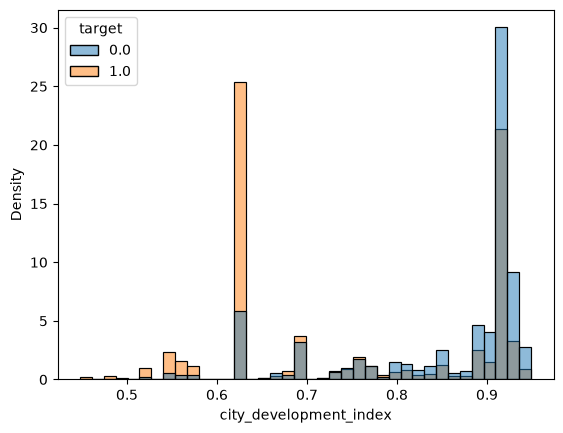

In [45]:
# Trace la distribution de l'indice de développement des villes selon la cible, avec une densité normalisée séparément pour chaque classe.
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x="city_development_index", hue="target",
             stat="density", common_norm=False)
plt.show()

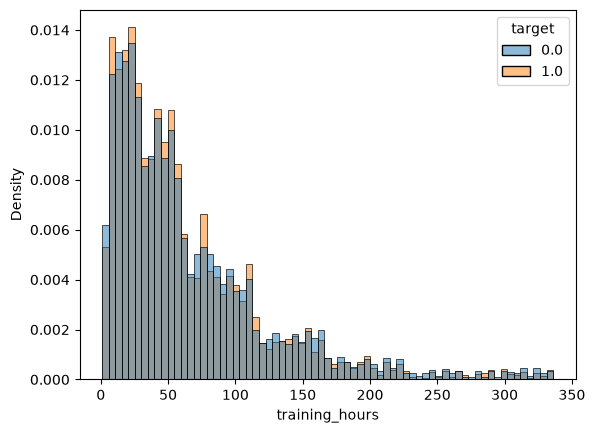

In [74]:
# Compare les distributions des heures de formation entre les candidats selon leur classe cible.
sns.histplot(data=df, x="training_hours", hue="target",
             stat="density", common_norm=False)
plt.show()

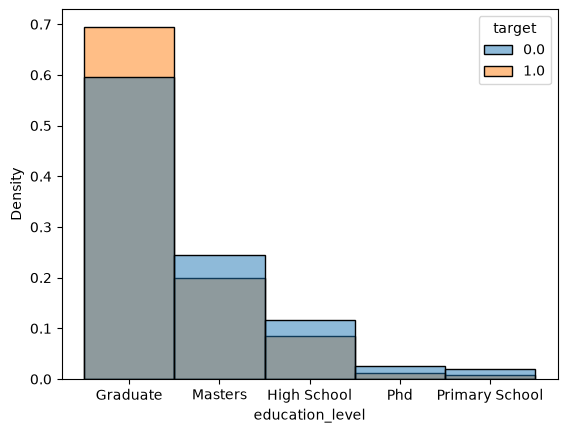

In [23]:
# Visualise la distribution du niveau d'études selon la classe cible pour comparer les deux groupes.
sns.histplot(data=df, x="education_level", hue="target",
             stat="density", common_norm=False)
plt.show()

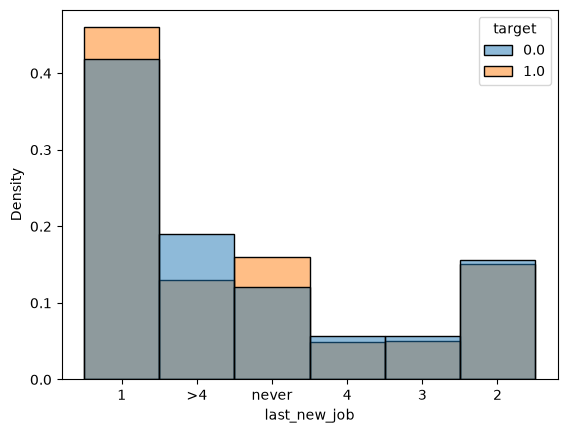

In [34]:
# Compare la distribution du délai depuis le dernier changement d'emploi selon la classe cible.
sns.histplot(data=df, x="last_new_job", hue="target", stat="density", common_norm=False)
plt.show()

In [56]:
# Regroupe l'indice de développement des villes en intervalles, puis affiche le taux de changement et l'effectif de chaque intervalle.
tranches = pd.cut(df["city_development_index"], bins=[0, 0.6, 0.65, 0.8, 0.9, 1.0])
print(df.groupby(tranches, observed=True)["target"].agg(["mean", "count"]))

                            mean  count
city_development_index                 
(0.0, 0.6]              0.579310    725
(0.6, 0.65]             0.582789   2754
(0.65, 0.8]             0.260153   2487
(0.8, 0.9]              0.135813   3549
(0.9, 1.0]              0.168309   9643


In [55]:
# Repère les villes les plus fréquentes parmi les candidats dont l'indice de développement est compris entre 0,62 et 0,63.
print(df[df["city_development_index"].between(0.62, 0.63)]["city"].value_counts().head())

city
city_21     2702
city_129       3
Name: count, dtype: int64


In [57]:
# Calcule la proportion de candidats cherchant à changer d'emploi dans la ville city_21.
print(df[df["city"] == "city_21"]["target"].mean())

0.5910436713545522


In [58]:
# Affiche les cinq villes les plus représentées dans l'ensemble des candidats.
print(df["city"].value_counts().head())

city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
Name: count, dtype: int64


In [60]:
# Vérifie combien de valeurs d'indice de développement différentes sont associées à une même ville au maximum.
print(df.groupby("city")["city_development_index"].nunique().max())

1


In [61]:
# Autorise pandas à afficher toutes les lignes des tableaux, au lieu de les tronquer.
pd.set_option("display.max_rows", None)

In [62]:
# Compare, pour chaque colonne incomplète, le taux de changement d'emploi chez les candidats ayant une valeur manquante ou renseignée.
rows = []
for col in df.columns[df.isna().any()]:
    vide = df[col].isna()
    rows.append({
        "colonne": col,
        "n_vides": vide.sum(),
        "taux_si_vide": df.loc[vide, "target"].mean(),
        "taux_si_rempli": df.loc[~vide, "target"].mean(),
    })
pd.DataFrame(rows).round(3)

,colonne,n_vides,taux_si_vide,taux_si_rempli
0,gender,4508,0.308,0.231
1,enrolled_university,386,0.319,0.248
2,education_level,460,0.226,0.250
3,major_discipline,2813,0.195,0.259
4,experience,65,0.354,0.249
5,company_size,5938,0.406,0.179
6,company_type,6140,0.388,0.184
7,last_new_job,423,0.364,0.247


In [63]:
# Réunit le classement des villes les plus fréquentes et la vérification de la stabilité de leur indice de développement.
print(df["city"].value_counts().head())
print(df.groupby("city")["city_development_index"].nunique().max())

city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
Name: count, dtype: int64
1


In [66]:
# Affiche les cinq villes les plus représentées dans l'ensemble des candidats.
print(df["city"].value_counts().head())

city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
Name: count, dtype: int64


In [48]:
# Calcule le taux moyen de changement d'emploi et l'effectif des candidats de city_103.
print(df[df["city"] == "city_103"]["target"].agg(["mean", "count"]))

mean        0.213088
count    4355.000000
Name: target, dtype: float64


In [49]:
# Calcule le taux moyen de changement d'emploi et l'effectif des candidats de city_21.
print(df[df["city"] == "city_21"]["target"].agg(["mean", "count"]))

mean        0.591044
count    2702.000000
Name: target, dtype: float64


In [57]:
# Affiche les villes les plus fréquentes parmi les candidats des villes à indice élevé (0,92 à 0,94).
print(df[df["city_development_index"].between(0.92, 0.94)]["city"].value_counts().head())

city
city_103    4355
city_114    1336
city_160     845
city_75      305
city_104     301
Name: count, dtype: int64


In [65]:
# Mesure le taux de changement d'emploi et l'effectif des candidats dont la taille d'entreprise est inconnue.
vide = df["company_size"].isna()
print(df.loc[vide, "target"].agg(["mean", "count"]))


mean        0.405861
count    5938.000000
Name: target, dtype: float64


In [67]:
# Regroupe l'indice de développement en intervalles et calcule le taux de changement et l'effectif par intervalle.
tranches = pd.cut(df["city_development_index"], bins=[0, 0.6, 0.65, 0.8, 0.9, 1.0])
df.groupby(tranches, observed=True)["target"].agg(["mean", "count"])

,mean,count
city_development_index,,
"(0.0, 0.6]",0.579310,725
"(0.6, 0.65]",0.582789,2754
"(0.65, 0.8]",0.260153,2487
"(0.8, 0.9]",0.135813,3549
"(0.9, 1.0]",0.168309,9643


In [74]:
# Chaque ville a-t-elle un seul indice de développement ?
print(df.groupby("city")["city_development_index"].nunique().max())

# Les heures de formation des deux groupes, en moyenne
print(df.groupby("target")["training_hours"].mean())

1
target
0.0    66.113761
1.0    63.118484
Name: training_hours, dtype: float64
